# Тестовая задача по работе с данными с использованием Python 

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

In [66]:
purchases = pd.read_csv('purchases.csv')
products = pd.read_csv('products.csv')

### Первичный анализ данных

In [67]:
print(purchases.info())
print(f"\nКоличество строк: {len(purchases)}")
print(f"Количество уникальных покупок: {purchases['purchaseID'].nunique()}")
print(f"Количество уникальных источников: {purchases['lastsignTrafficSource'].nunique()}")

<class 'pandas.DataFrame'>
RangeIndex: 6462 entries, 0 to 6461
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   lastsignTrafficSource  6462 non-null   str    
 1   purchaseID             6462 non-null   int64  
 2   purchaseRevenue        6462 non-null   float64
 3   purchaseDateTime       6462 non-null   str    
dtypes: float64(1), int64(1), str(2)
memory usage: 202.1 KB
None

Количество строк: 6462
Количество уникальных покупок: 6462
Количество уникальных источников: 9


In [68]:
purchases.head()

,lastsignTrafficSource,purchaseID,purchaseRevenue,purchaseDateTime
0,organic,60337498,2845.0,2025-05-27 10:19:03
1,organic,60335988,7830.0,2025-05-24 16:30:01
2,ad,60334562,9319.0,2025-05-22 01:59:54
3,direct,60336983,6889.0,2025-05-26 12:11:20
4,direct,60336989,4549.0,2025-05-26 12:16:08


In [69]:
print(products.info())
print(f"\nКоличество строк: {len(products)}")
print(f"Количество уникальных товаров: {products['productsID'].nunique()}")
print(f"Количество уникальных покупок в products: {products['productsPurchaseID'].nunique()}")

<class 'pandas.DataFrame'>
RangeIndex: 20769 entries, 0 to 20768
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   productsPurchaseID  20769 non-null  int64  
 1   productsID          20769 non-null  int64  
 2   productsPrice       20769 non-null  float64
dtypes: float64(1), int64(2)
memory usage: 486.9 KB
None

Количество строк: 20769
Количество уникальных товаров: 4523
Количество уникальных покупок в products: 6462


In [70]:
products.head()

,productsPurchaseID,productsID,productsPrice
0,60323068,58627,4590.0
1,60323068,137958,0.0
2,60324684,28543,3391.0
3,60324684,137958,0.0
4,60329108,1921,16310.0


In [71]:
purchases['purchaseDateTime'] = pd.to_datetime(purchases['purchaseDateTime'], errors='coerce')
print(f"Диапазон дат: {purchases['purchaseDateTime'].min()} - {purchases['purchaseDateTime'].max()}")
last_date = purchases['purchaseDateTime'].max().date()
last_day_count = len(purchases[purchases['purchaseDateTime'].dt.date == last_date])
print(f"Последний день ({last_date}) содержит {last_day_count} запись")

Диапазон дат: 2025-05-01 00:39:02 - 2025-06-01 00:01:40
Последний день (2025-06-01) содержит 1 запись


####  1 июня - это последний день в датасете со временем 00:01:40, поэтому данные в этот день крайне неполные и их следует исключить. 

In [72]:
full_data = purchases[purchases['purchaseDateTime'].dt.date < last_date].copy()
full_data['purchaseDate'] = full_data['purchaseDateTime'].dt.date
merged = full_data.merge(products, left_on='purchaseID', right_on='productsPurchaseID', how='inner')

### 1 вопрос: Количество товаров по источникам

In [73]:
source_products_count = merged.groupby('lastsignTrafficSource')['productsID'].count().sort_values(ascending=False)
print(source_products_count)
print(f"\nБольше всего товаров куплено в источнике '{source_products_count.index[0]}' - {source_products_count.iloc[0]} товаров")

lastsignTrafficSource
ad           8590
organic      7484
referral     1933
direct       1649
email         667
internal      360
messenger      42
social         32
recommend      11
Name: productsID, dtype: int64

Больше всего товаров куплено в источнике 'ad' - 8590 товаров


### 2 вопрос: Уникальные товары по дням

In [74]:
daily_unique_products = merged.groupby('purchaseDate')['productsID'].nunique().sort_values(ascending=False)
print(f"Максимальное количество уникальных товаров за день: {daily_unique_products.max()}")
print(f"Дата с максимальным количеством: {daily_unique_products.index[0]}")
print(f"Топ-5 дней:")
print(daily_unique_products.head())

Максимальное количество уникальных товаров за день: 413
Дата с максимальным количеством: 2025-05-14
Топ-5 дней:
purchaseDate
2025-05-14    413
2025-05-20    379
2025-05-13    375
2025-05-12    365
2025-05-15    354
Name: productsID, dtype: int64


### 3 вопрос: Дни с наименьшим количеством покупок

In [75]:
daily_purchases = full_data.groupby(purchases['purchaseDateTime'].dt.date)['purchaseID'].count().sort_values()
print(f"Дата с минимальным количеством покупок: {daily_purchases.index[0]}")
print(f"Количество покупок: {daily_purchases.iloc[0]}")
print(f"Топ-5 дней с наименьшим количеством покупок:")
print(daily_purchases.head())

Дата с минимальным количеством покупок: 2025-05-09
Количество покупок: 137
Топ-5 дней с наименьшим количеством покупок:
purchaseDateTime
2025-05-09    137
2025-05-24    141
2025-05-31    157
2025-05-03    165
2025-05-01    169
Name: purchaseID, dtype: int64


### 4 вопрос: Максимальное падение для organic

In [76]:
organic_purchases = full_data[full_data['lastsignTrafficSource'] == 'organic'].copy()
organic_daily = organic_purchases.groupby(organic_purchases['purchaseDateTime'].dt.date)['purchaseID'].count()
organic_daily = organic_daily.sort_index()

daily_drop = []
for i in range(1, len(organic_daily)):
    prev_count = organic_daily.iloc[i-1]
    curr_count = organic_daily.iloc[i]
    if prev_count > 0:
        drop_percent = ((prev_count - curr_count) / prev_count) * 100
        if drop_percent > 0:
            daily_drop.append({
                'date': organic_daily.index[i],
                'prev_date': organic_daily.index[i-1],
                'prev_count': prev_count,
                'curr_count': curr_count,
                'drop_percent': drop_percent
            })

if daily_drop:
    max_drop = max(daily_drop, key=lambda x: x['drop_percent'])
    print(f"Максимальное падение: {max_drop['drop_percent']:.2f}%")
    print(f"Период: с {max_drop['prev_date']} до {max_drop['date']}")
    print(f"Количество покупок: с {max_drop['prev_count']} до {max_drop['curr_count']}")
else:
    print("Нет падений в данных")

Максимальное падение: 29.89%
Период: с 2025-05-16 до 2025-05-17
Количество покупок: с 87 до 61


## Визуализация

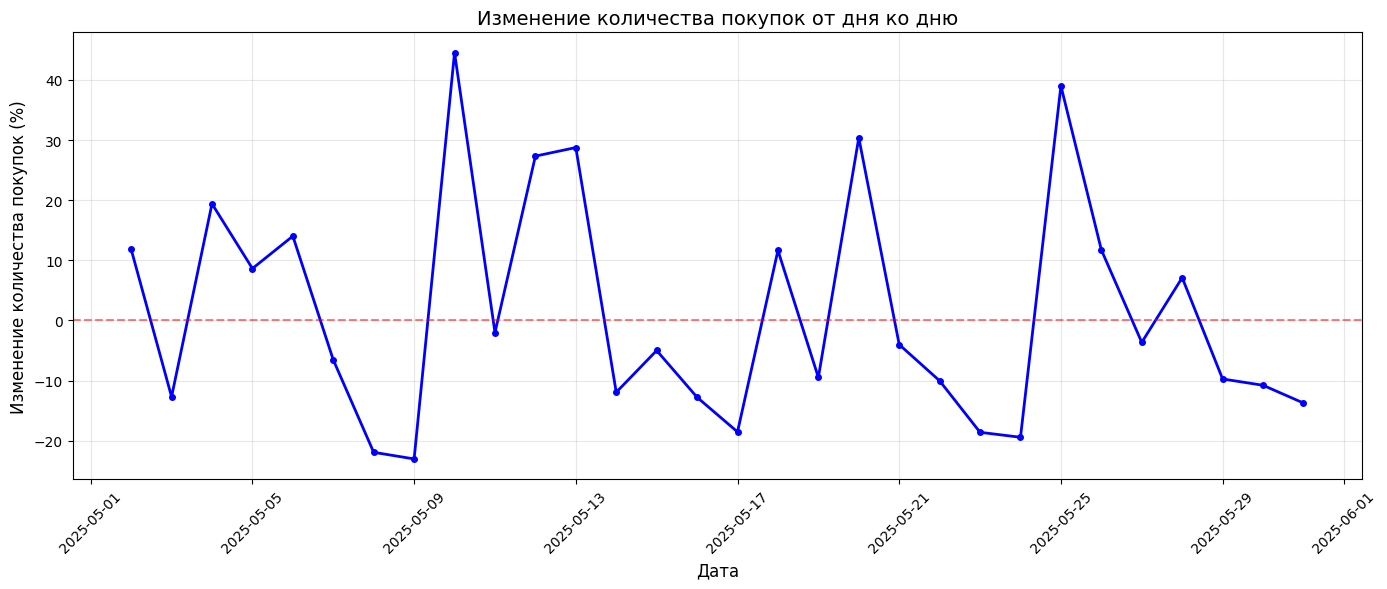

In [77]:
last_date = full_data['purchaseDateTime'].max().date()
month_ago = last_date - timedelta(days=30)
monthly_data = full_data[full_data['purchaseDate'] >= month_ago].copy()
monthly_daily = monthly_data.groupby(monthly_data['purchaseDateTime'].dt.date)['purchaseID'].count().sort_index()
percent_changes = monthly_daily.pct_change() * 100
percent_changes = percent_changes.dropna()

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(percent_changes.index, percent_changes.values, marker='o', linestyle='-', linewidth=2, markersize=4, color='blue')
ax.axhline(y=0, color='red', linestyle='--', alpha=0.5)
ax.set_xlabel('Дата', fontsize=12)
ax.set_ylabel('Изменение количества покупок (%)', fontsize=12)
ax.set_title('Изменение количества покупок от дня ко дню', fontsize=14)
ax.tick_params(axis='x', rotation=45)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('purchases_change_by_day.png', dpi=300)
plt.show()

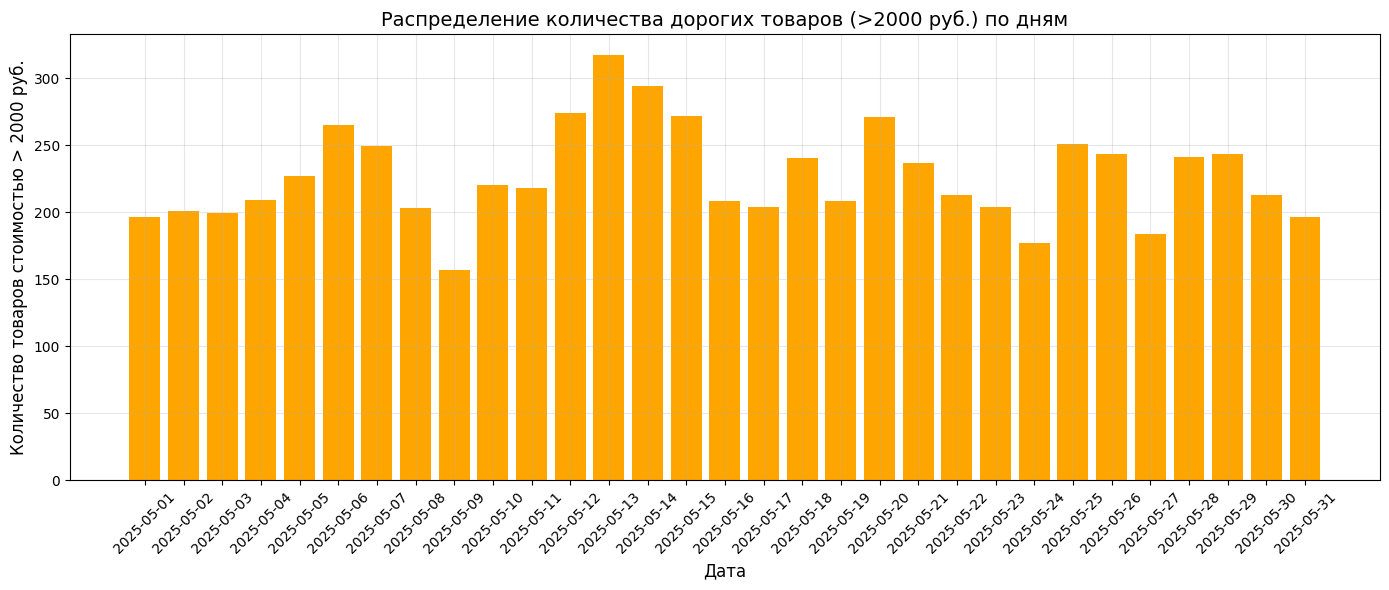

Всего товаров дороже 2000: 7035
Количество дней в анализе: 31
Среднее в день: 226.90


In [78]:
expensive_products = products[products['productsPrice'] > 2000].copy()
expensive_merged = expensive_products.merge(
    full_data[['purchaseID', 'purchaseDateTime']], 
    left_on='productsPurchaseID', 
    right_on='purchaseID', 
    how='inner'
)
expensive_daily = expensive_merged.groupby(expensive_merged['purchaseDateTime'].dt.date)['productsID'].count()

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(expensive_daily.index.astype(str), expensive_daily.values, width=0.8, color='orange')
ax.set_xlabel('Дата', fontsize=12)
ax.set_ylabel('Количество товаров стоимостью > 2000 руб.', fontsize=12)
ax.set_title('Распределение количества дорогих товаров (>2000 руб.) по дням', fontsize=14)
ax.tick_params(axis='x', rotation=45)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('expensive_products_by_day.png', dpi=300)
plt.show()

print(f"Всего товаров дороже 2000: {len(expensive_products)}")
print(f"Количество дней в анализе: {len(expensive_daily)}")
print(f"Среднее в день: {expensive_daily.mean():.2f}")

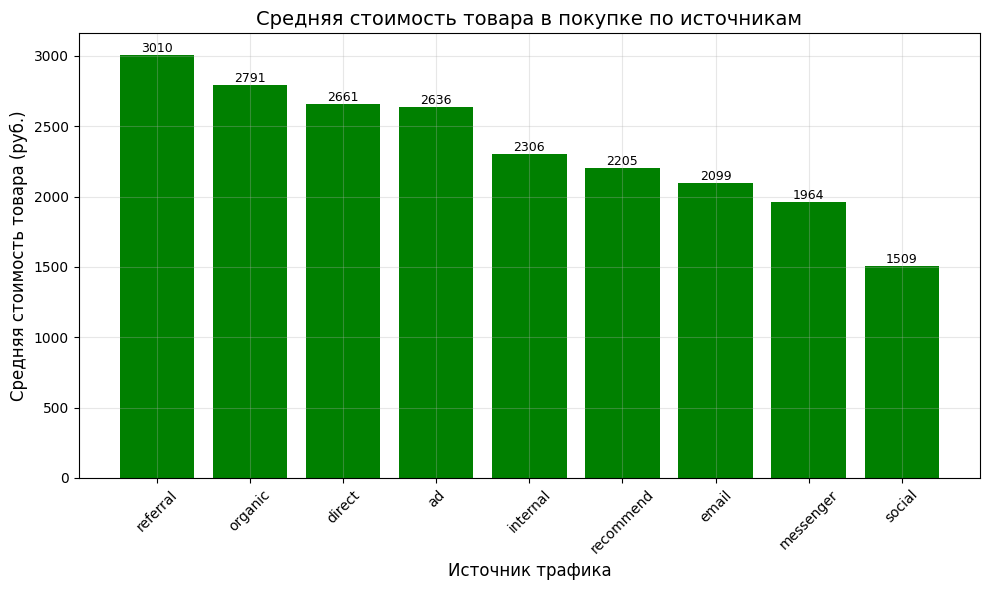

lastsignTrafficSource
referral     3010.067770
organic      2790.629343
direct       2660.836264
ad           2636.252154
internal     2306.291667
recommend    2205.000000
email        2098.502249
messenger    1964.309524
social       1509.250000
Name: productsPrice, dtype: float64


In [79]:
avg_product_price_by_source = merged.groupby('lastsignTrafficSource')['productsPrice'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(avg_product_price_by_source.index, avg_product_price_by_source.values, color='green')
ax.set_xlabel('Источник трафика', fontsize=12)
ax.set_ylabel('Средняя стоимость товара (руб.)', fontsize=12)
ax.set_title('Средняя стоимость товара в покупке по источникам', fontsize=14)
ax.tick_params(axis='x', rotation=45)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.0f}',
            ha='center', va='bottom', fontsize=9)

ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('avg_price_by_source.png', dpi=300)
plt.show()
print(avg_product_price_by_source)

# Выводы

### Анализ источников трафика
Доминирование рекламы (ad): 41.4% основной канал

Organic на втором месте: 36% хороший органический трафик

Остальные каналы слабые: referral (9.3%), direct (7.9%)

Проблемные каналы: messenger, social, recommend - менее 0.5% каждый 

### Сезонность и динамика продаж
Пик: 14 мая - максимальные продажи (413 уникальных товаров)

Спад: 9 мая - минимальные продажи (137 товаров)

Выходные: 24 мая (суббота) и 31 мая (суббота) - низкие продажи

1) Анализировать причины пика 14 мая для повторения успеха
2) Разработать акции для слабых дней (особенно выходные)

### Анализ падений
Резкое падение 16-17 мая: 29.89% 

1) Проверить логи за 16-17 мая
2) Сравнить с аналогичными днями недели
3) Разработать план действий при резких падениях
   
### Анализ дорогого сегмента
Высокая доля дорогих товаров

Стабильный спрос: в среднем 227 дорогих товаров в день


1) Сфокусироваться на продвижении дорогих товаров
2) Анализировать, какие дорогие товары продаются лучше
3) Разработать кросс-продажи для дорогих товаров
   
### Средняя стоимость по источникам
Referral премиум-канал: самая высокая средняя цена (3010 руб.)

Organic качественный трафик: вторая по цене (2791 руб.)

Social самый дешевый: средняя цена всего 1509 руб

1) Инвестировать в referral 
2) Улучшать качество organic трафика
3) Пересмотреть стратегию для social 

### Усложненная задача

In [80]:
raw_purchases = pd.read_csv('raw_purchases.csv')
raw_products = pd.read_csv('raw_products.csv')

In [81]:
raw_purchases.info()

<class 'pandas.DataFrame'>
RangeIndex: 5802 entries, 0 to 5801
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   lastsignTrafficSource  5802 non-null   str  
 1   purchaseID             5802 non-null   str  
 2   purchaseRevenue        5802 non-null   str  
 3   purchaseDateTime       5802 non-null   str  
dtypes: str(4)
memory usage: 181.4 KB


In [82]:
raw_purchases.describe()

,lastsignTrafficSource,purchaseID,purchaseRevenue,purchaseDateTime
count,5802,5802,5802,5802
unique,9,5802,3673,5796
top,ad,['60337498'],[10850.0],[\'2025-05-02 10:47:55\']
freq,2366,1,32,2


In [83]:
raw_purchases.head()

,lastsignTrafficSource,purchaseID,purchaseRevenue,purchaseDateTime
0,organic,['60337498'],[2845.0],[\'2025-05-27 10:19:03\']
1,organic,['60335988'],[7830.0],[\'2025-05-24 16:30:01\']
2,ad,['60334562'],[9319.0],[\'2025-05-22 01:59:54\']
3,direct,"['60336983','60336989']","[6889.0,4549.0]","[\'2025-05-26 12:11:20\',\'2025-05-26 12:16:08\']"
4,organic,['60327247'],[3400.0],[\'2025-05-11 09:50:52\']


In [84]:
raw_products.info()

<class 'pandas.DataFrame'>
RangeIndex: 5802 entries, 0 to 5801
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   productsPurchaseID  5802 non-null   str  
 1   productsID          5802 non-null   str  
 2   productsPrice       5802 non-null   str  
dtypes: str(3)
memory usage: 136.1 KB


In [85]:
raw_products.describe()

,productsPurchaseID,productsID,productsPrice
count,5802,5802,5802
unique,5802,4714,4392
top,"['60323068','60323068']",['143827'],[2677000000]
freq,1,16,19


In [86]:
raw_products.head()

,productsPurchaseID,productsID,productsPrice
0,"['60323068','60323068']","['58627','137958']","[4590000000,0]"
1,"['60324684','60324684']","['28543','137958']","[3391000000,0]"
2,"['60329108','60329103']","['1921','1921']","[16310000000,16310000000]"
3,['60326705'],['140727'],[5550000000]
4,"['60330472','60330472','60330472','60330472','...","['18636','286864','137958','294093','292915']","[12190000000,0,0,0,0]"


In [87]:
#очистка от лишних символов
def clean_string(value):
    if pd.isna(value) or value == '':
        return value
    value = str(value)
    value = value.replace("\\'", "'")  
    value = value.replace('\\"', '"') 
    value = value.replace('\\\\', '\\') 
    return value

In [88]:
#преобразование строки в список
def parse_list_string(value):
    
    if pd.isna(value) or value == '':
        return []
    value = clean_string(value)
    
    try:
        result = ast.literal_eval(value)
        if not isinstance(result, list):
            return [result]
        return result
    except:
        try:
            cleaned = value.strip('[]')
            items = [x.strip().strip("'").strip('"') for x in cleaned.split(',') if x.strip()]
            return items
        except:
            return [value]

In [89]:
#преобразование raw_purchases в формат purchases
def transform_raw_purchases(raw_df):
    transformed_rows = []

    for idx, row in raw_df.iterrows():
        source = clean_string(row['lastsignTrafficSource'])
        if source.startswith('['):
            source_list = parse_list_string(source)
            source = source_list[0] if source_list else 'unknown'

        purchase_ids = parse_list_string(row['purchaseID'])
        revenues = parse_list_string(row['purchaseRevenue'])
        datetimes = parse_list_string(row['purchaseDateTime'])
        
        datetimes = [clean_string(d) for d in datetimes]
        max_len = max(len(purchase_ids), len(revenues), len(datetimes))
        
        if len(purchase_ids) == 0:
            purchase_ids = [f'UNKNOWN_{idx}_{i}' for i in range(max_len)]
        if len(revenues) == 0:
            revenues = ['0'] * max_len
        if len(datetimes) == 0:
            datetimes = [pd.NaT] * max_len

        while len(purchase_ids) < max_len:
            purchase_ids.append(purchase_ids[-1] if purchase_ids else f'UNKNOWN_{idx}_{len(purchase_ids)}')
        while len(revenues) < max_len:
            revenues.append(revenues[-1] if revenues else '0')
        while len(datetimes) < max_len:
            datetimes.append(datetimes[-1] if datetimes else pd.NaT)

        for i in range(max_len):
            try:
                dt = pd.to_datetime(datetimes[i], errors='coerce') if i < len(datetimes) else pd.NaT
            except:
                dt = pd.NaT
            try:
                revenue = float(revenues[i]) if i < len(revenues) else 0.0
            except:
                revenue = 0.0
            
            transformed_rows.append({
                'lastsignTrafficSource': source,
                'purchaseID': purchase_ids[i] if i < len(purchase_ids) else f'UNKNOWN_{idx}_{i}',
                'purchaseRevenue': revenue,
                'purchaseDateTime': dt
            })
    
    result = pd.DataFrame(transformed_rows)
    result = result.drop_duplicates(subset=['purchaseID'])
    result = result[result['purchaseRevenue'] >= 0]
    result = result.dropna(subset=['purchaseDateTime'])
    
    return result

transformed_purchases = transform_raw_purchases(raw_purchases)

In [90]:
transformed_purchases.head()

,lastsignTrafficSource,purchaseID,purchaseRevenue,purchaseDateTime
0,organic,60337498,2845.0,2025-05-27 10:19:03
1,organic,60335988,7830.0,2025-05-24 16:30:01
2,ad,60334562,9319.0,2025-05-22 01:59:54
3,direct,60336983,6889.0,2025-05-26 12:11:20
4,direct,60336989,4549.0,2025-05-26 12:16:08


In [91]:
transformed_purchases.info()

<class 'pandas.DataFrame'>
RangeIndex: 6462 entries, 0 to 6461
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   lastsignTrafficSource  6462 non-null   str           
 1   purchaseID             6462 non-null   str           
 2   purchaseRevenue        6462 non-null   float64       
 3   purchaseDateTime       6462 non-null   datetime64[us]
dtypes: datetime64[us](1), float64(1), str(2)
memory usage: 202.1 KB


In [92]:
#преобразование raw_products в формат products
def transform_raw_products(raw_df):
    transformed_rows = []
    
    for idx, row in raw_df.iterrows():
        purchase_ids = parse_list_string(row['productsPurchaseID'])
        product_ids = parse_list_string(row['productsID'])
        prices = parse_list_string(row['productsPrice'])

        max_len = max(len(purchase_ids), len(product_ids), len(prices))
        
        if len(purchase_ids) == 0:
            purchase_ids = [f'UNKNOWN_{idx}_{i}' for i in range(max_len)]
        if len(product_ids) == 0:
            product_ids = ['0'] * max_len
        if len(prices) == 0:
            prices = ['0'] * max_len

        while len(purchase_ids) < max_len:
            purchase_ids.append(purchase_ids[-1] if purchase_ids else f'UNKNOWN_{idx}_{len(purchase_ids)}')
        while len(product_ids) < max_len:
            product_ids.append(product_ids[-1] if product_ids else '0')
        while len(prices) < max_len:
            prices.append(prices[-1] if prices else '0')
        
        for i in range(max_len):
            try:
                price = float(prices[i]) if i < len(prices) else 0.0
                if price > 1000000000:
                    price = price / 100
            except:
                price = 0.0
            try:
                product_id = int(product_ids[i]) if i < len(product_ids) and product_ids[i].lstrip('-').isdigit() else 0
            except:
                product_id = 0
            
            transformed_rows.append({
                'productsPurchaseID': purchase_ids[i] if i < len(purchase_ids) else f'UNKNOWN_{idx}_{i}',
                'productID': product_id,
                'productsPrice': price
            })
    
    result = pd.DataFrame(transformed_rows)
    result = result.drop_duplicates(subset=['productsPurchaseID', 'productID'])
    result = result[result['productsPrice'] >= 0]
    result = result[result['productID'] != 0]
    return result
    
transformed_products = transform_raw_products(raw_products)

In [93]:
transformed_products.head()

,productsPurchaseID,productID,productsPrice
0,60323068,58627,45900000.0
1,60323068,137958,0.0
2,60324684,28543,33910000.0
3,60324684,137958,0.0
4,60329108,1921,163100000.0


In [94]:
transformed_products.info()

<class 'pandas.DataFrame'>
RangeIndex: 20769 entries, 0 to 20768
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   productsPurchaseID  20769 non-null  str    
 1   productID           20769 non-null  int64  
 2   productsPrice       20769 non-null  float64
dtypes: float64(1), int64(1), str(1)
memory usage: 486.9 KB
